<a href="https://colab.research.google.com/github/anisha-dev26/BIS_LAB-1BF24CS054-/blob/main/Parallel_Cellular_Algo(Machine_Learning).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Historical land-use maps generated.


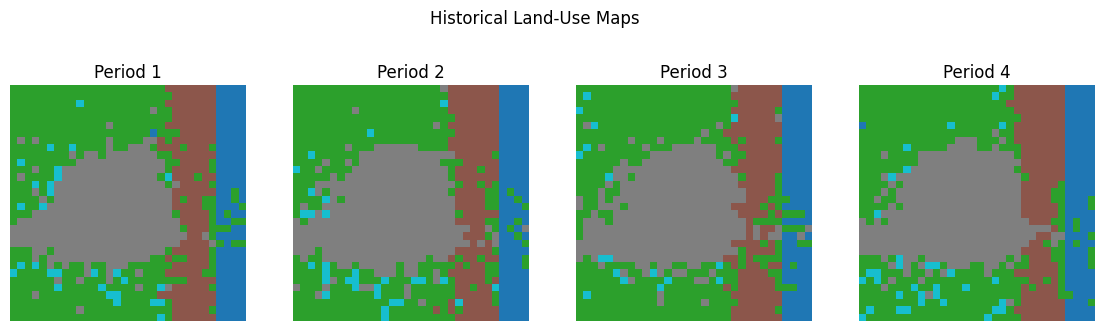


CNN-LSTM Training
Generation 1: Fitness/Loss = 1.5594
Generation 2: Fitness/Loss = 1.3692
Generation 3: Fitness/Loss = 0.9500
Generation 4: Fitness/Loss = 0.5627
Generation 5: Fitness/Loss = 0.4283
Generation 6: Fitness/Loss = 0.3853
Generation 7: Fitness/Loss = 0.3730
Generation 8: Fitness/Loss = 0.3623
Generation 9: Fitness/Loss = 0.3516
Generation 10: Fitness/Loss = 0.3467
Generation 11: Fitness/Loss = 0.3440
Generation 12: Fitness/Loss = 0.3458

CNN-LSTM prediction completed.
XGBoost training completed.

Weight Optimization
Generation 1: Fitness = 0.7846, Kappa = 0.9008, FoM = 0.6684
Generation 2: Fitness = 0.6783, Kappa = 0.8404, FoM = 0.5161
Generation 3: Fitness = 0.7846, Kappa = 0.9008, FoM = 0.6684
Generation 4: Fitness = 0.7837, Kappa = 0.9008, FoM = 0.6667
Generation 5: Fitness = 0.6813, Kappa = 0.8418, FoM = 0.5207
Generation 6: Fitness = 0.6530, Kappa = 0.8311, FoM = 0.4749
Generation 7: Fitness = 0.7878, Kappa = 0.9022, FoM = 0.6735
Generation 8: Fitness = 0.7337, Kappa 

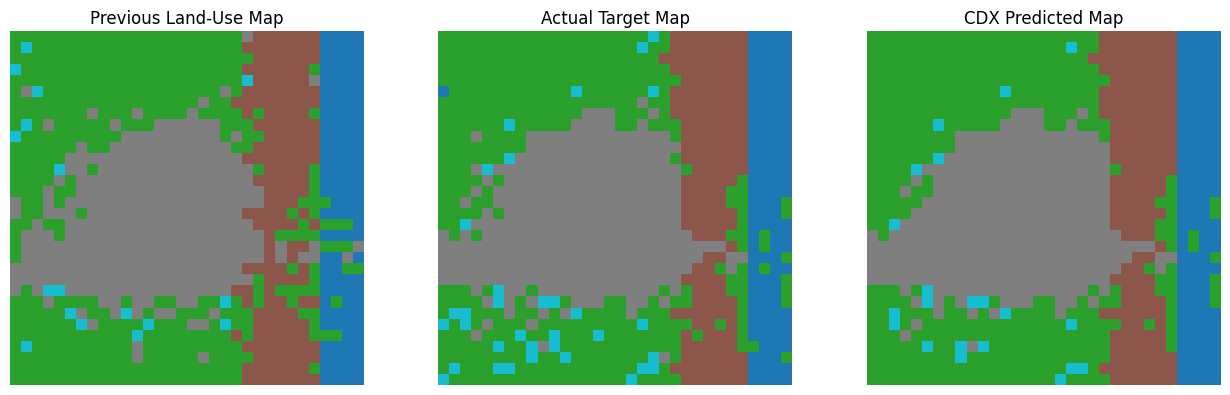

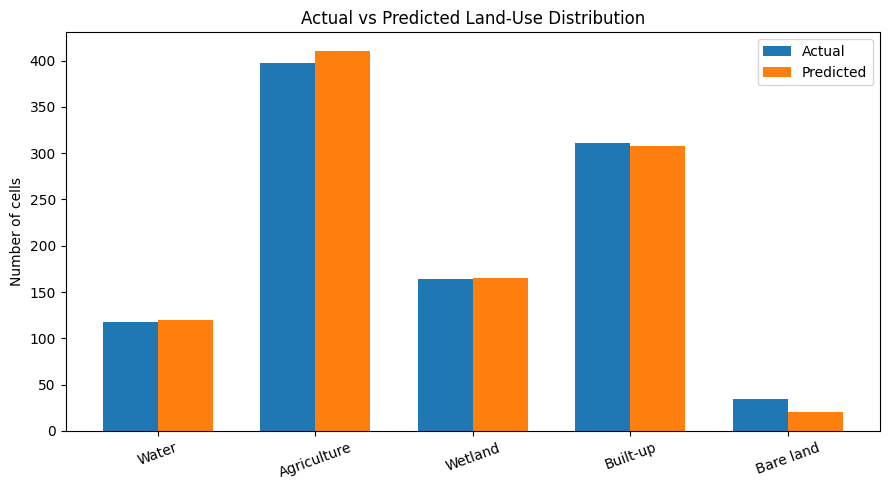

In [1]:

# CDX: Cellular Automata + CNN-LSTM + XGBoost
# Simplified educational implementation for Google Colab

!pip -q install xgboost

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier
from scipy.ndimage import uniform_filter
from sklearn.metrics import cohen_kappa_score
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. SETTINGS
# --------------------------------------------------

np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SIZE = 32
NUM_CLASSES = 5
NUM_EPOCHS = 12
BATCH_SIZE = 64
NUM_WEIGHT_TRIALS = 100

CLASS_NAMES = [
    "Water", "Agriculture", "Wetland", "Built-up", "Bare land"
]

# --------------------------------------------------
# 2. GENERATE SAMPLE LAND-USE MAPS
# --------------------------------------------------
# This is synthetic data for demonstration.
# It is NOT actual Yancheng satellite data.

x, y = np.meshgrid(
    np.linspace(0, 1, SIZE),
    np.linspace(0, 1, SIZE)
)

def generate_land_map(year_index):
    center = np.exp(
        -((x - 0.45)**2 + (y - 0.48)**2) / 0.035
    )

    road = np.exp(-((y - 0.65)**2) / 0.006)

    water = 1.2 * (x > 0.88) + 0.5 * np.exp(
        -((y - 0.2)**2) / 0.02
    )

    wetland = 1.2 * np.exp(
        -((x - 0.78)**2) / 0.025
    )

    agriculture = 0.8 + 0.3 * np.sin(5*x) * np.cos(5*y)

    urban = (
        0.5 + 1.8 * center +
        0.6 * road + 0.25 * year_index * center
    )

    bare = 0.3 + 0.4 * np.random.random((SIZE, SIZE))

    scores = np.stack([
        water,
        agriculture,
        wetland,
        urban,
        bare
    ], axis=-1)

    scores += np.random.normal(
        0, 0.12, scores.shape
    )

    return np.argmax(scores, axis=-1).astype(np.int64)


maps = [
    generate_land_map(i) for i in range(4)
]

print("Historical land-use maps generated.")

# --------------------------------------------------
# 3. DISPLAY HISTORICAL MAPS
# --------------------------------------------------

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, ax in enumerate(axes):
    ax.imshow(maps[i], cmap="tab10", vmin=0, vmax=4)
    ax.set_title(f"Period {i+1}")
    ax.axis("off")

plt.suptitle("Historical Land-Use Maps")
plt.show()

# --------------------------------------------------
# 4. GENERATE 13 DRIVING FACTORS
# --------------------------------------------------
# Examples: elevation, slope, population, GDP,
# road distance, water distance, vegetation indices.

drivers = np.stack([
    x,
    y,
    x*y,
    np.sqrt((x-0.5)**2 + (y-0.5)**2),
    np.exp(-((x-0.5)**2 + (y-0.5)**2)/0.05),
    np.sin(3*x),
    np.cos(3*y),
    np.random.random((SIZE, SIZE)),
    np.random.random((SIZE, SIZE)),
    np.exp(-((y-0.65)**2)/0.01),
    np.exp(-((x-0.85)**2)/0.02),
    np.sin(4*x)*np.cos(4*y),
    np.random.random((SIZE, SIZE))
], axis=-1).astype(np.float32)

# --------------------------------------------------
# 5. PREPARE CNN-LSTM INPUT PATCHES
# --------------------------------------------------

def create_patches(historical_maps, patch_size=5):
    radius = patch_size // 2
    samples = []

    padded_maps = []

    for land_map in historical_maps:
        one_hot = np.eye(NUM_CLASSES)[land_map]
        padded = np.pad(
            one_hot,
            ((radius, radius), (radius, radius), (0, 0)),
            mode="edge"
        )
        padded_maps.append(padded)

    for row in range(SIZE):
        for col in range(SIZE):
            sequence = []

            for padded in padded_maps:
                patch = padded[
                    row:row+patch_size,
                    col:col+patch_size,
                    :
                ]

                # CNN input: channels, height, width
                patch = np.transpose(patch, (2, 0, 1))
                sequence.append(patch)

            samples.append(sequence)

    return np.array(samples, dtype=np.float32)


# Use first three maps to predict the fourth map
X_sequence = create_patches(maps[:3])
y_target = maps[3].flatten()

X_tensor = torch.tensor(X_sequence)
y_tensor = torch.tensor(y_target, dtype=torch.long)

dataset = TensorDataset(X_tensor, y_tensor)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# --------------------------------------------------
# 6. CNN-LSTM MODEL
# --------------------------------------------------

class CNNLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(5, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.lstm = nn.LSTM(
            input_size=32,
            hidden_size=64,
            batch_first=True
        )

        self.fc = nn.Linear(64, NUM_CLASSES)

    def forward(self, inputs):
        batch, steps, channels, height, width = inputs.shape

        inputs = inputs.reshape(
            batch * steps, channels, height, width
        )

        features = self.cnn(inputs)
        features = features.view(batch, steps, 32)

        output, _ = self.lstm(features)

        return self.fc(output[:, -1, :])


model = CNNLSTM().to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

# --------------------------------------------------
# 7. TRAIN CNN-LSTM
# --------------------------------------------------

print("\nCNN-LSTM Training")

for epoch in range(NUM_EPOCHS):

    model.train()
    total_loss = 0

    for batch_x, batch_y in loader:

        batch_x = batch_x.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(loader)

    print(
        f"Generation {epoch+1}: "
        f"Fitness/Loss = {average_loss:.4f}"
    )

# CNN-LSTM probabilities
model.eval()

with torch.no_grad():
    dl_logits = model(X_tensor.to(DEVICE))
    dl_prob = torch.softmax(dl_logits, dim=1)
    dl_prob = dl_prob.cpu().numpy()

print("\nCNN-LSTM prediction completed.")

# --------------------------------------------------
# 8. XGBOOST DRIVER SUITABILITY MODEL
# --------------------------------------------------

# Driving factors + current land-use category
current_map = maps[2]

driver_features = drivers.reshape(-1, 13)

current_onehot = np.eye(NUM_CLASSES)[
    current_map.flatten()
]

X_xgb = np.concatenate(
    [driver_features, current_onehot],
    axis=1
)

y_xgb = maps[3].flatten()

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.08,
    objective="multi:softprob",
    num_class=NUM_CLASSES,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_xgb, y_xgb)

xgb_raw = xgb_model.predict_proba(X_xgb)

# Ensure probabilities follow class order 0,1,2,3,4
xgb_prob = np.zeros(
    (SIZE*SIZE, NUM_CLASSES)
)

for index, class_id in enumerate(xgb_model.classes_):
    xgb_prob[:, int(class_id)] = xgb_raw[:, index]

print("XGBoost training completed.")

# --------------------------------------------------
# 9. CELLULAR AUTOMATA NEIGHBOURHOOD EFFECT
# --------------------------------------------------

def calculate_ca_potential(land_map):

    ca_prob = np.zeros(
        (SIZE, SIZE, NUM_CLASSES)
    )

    for class_id in range(NUM_CLASSES):

        binary_map = (
            land_map == class_id
        ).astype(float)

        # 5 x 5 neighbourhood
        neighbourhood = uniform_filter(
            binary_map,
            size=5,
            mode="nearest"
        )

        ca_prob[:, :, class_id] = neighbourhood

    ca_prob = ca_prob.reshape(
        -1, NUM_CLASSES
    )

    ca_prob += 1e-6

    ca_prob /= ca_prob.sum(
        axis=1, keepdims=True
    )

    return ca_prob


ca_prob = calculate_ca_potential(current_map)

# --------------------------------------------------
# 10. COMBINE THE THREE COMPONENTS
# --------------------------------------------------

def softmax(values):
    values = values - np.max(
        values, axis=1, keepdims=True
    )

    exp_values = np.exp(values)

    return exp_values / exp_values.sum(
        axis=1, keepdims=True
    )


def predict_cdx(weights):

    w1, w2, w3 = weights

    # Convert probabilities into logit scores
    z_dl = np.log(dl_prob + 1e-8)
    z_xgb = np.log(xgb_prob + 1e-8)
    z_ca = np.log(ca_prob + 1e-8)

    # Weighted fusion from the paper
    total_logits = (
        w1 * z_dl +
        w2 * z_xgb +
        w3 * z_ca
    )

    return softmax(total_logits)


# --------------------------------------------------
# 11. EVALUATION METRICS
# --------------------------------------------------

def calculate_fom(actual, predicted, previous):

    actual_change = actual != previous
    predicted_change = predicted != previous

    hits = np.sum(
        actual_change & predicted_change
    )

    misses = np.sum(
        actual_change & ~predicted_change
    )

    false_alarms = np.sum(
        ~actual_change & predicted_change
    )

    denominator = hits + misses + false_alarms

    if denominator == 0:
        return 0.0

    return hits / denominator


def evaluate(actual, predicted, previous):

    kappa = cohen_kappa_score(
        actual.flatten(),
        predicted.flatten()
    )

    fom = calculate_fom(
        actual.flatten(),
        predicted.flatten(),
        previous.flatten()
    )

    return kappa, fom


# --------------------------------------------------
# 12. OPTIMIZE WEIGHTS USING DIRICHLET SAMPLING
# --------------------------------------------------

actual_map = maps[3]

best_fitness = -np.inf
best_weights = None
best_prediction = None

print("\nWeight Optimization")

for generation in range(NUM_WEIGHT_TRIALS):

    # Weights sum to 1
    weights = np.random.dirichlet(
        [1, 1, 1]
    )

    probabilities = predict_cdx(weights)

    prediction = np.argmax(
        probabilities, axis=1
    ).reshape(SIZE, SIZE)

    kappa, fom = evaluate(
        actual_map,
        prediction,
        current_map
    )

    # Paper objective: lambda1 = lambda2 = 0.5
    fitness = 0.5 * kappa + 0.5 * fom

    if fitness > best_fitness:

        best_fitness = fitness
        best_weights = weights
        best_prediction = prediction.copy()

    print(
        f"Generation {generation+1}: "
        f"Fitness = {fitness:.4f}, "
        f"Kappa = {kappa:.4f}, "
        f"FoM = {fom:.4f}"
    )


# --------------------------------------------------
# 13. FINAL RESULTS
# --------------------------------------------------

print("\n========== FINAL CDX RESULTS ==========")

print("Best CNN-LSTM weight:", round(best_weights[0], 4))
print("Best XGBoost weight:", round(best_weights[1], 4))
print("Best CA weight:", round(best_weights[2], 4))

print("Best Fitness:", round(best_fitness, 4))

final_kappa, final_fom = evaluate(
    actual_map,
    best_prediction,
    current_map
)

print("Final Kappa:", round(final_kappa, 4))
print("Final Figure of Merit:", round(final_fom, 4))

print("\nPredicted Land-Use Distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(best_prediction == class_id)

    print(
        class_name, ":", count, "cells"
    )


# --------------------------------------------------
# 14. PLOT ACTUAL VS PREDICTED MAP
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(
    current_map, cmap="tab10", vmin=0, vmax=4
)
axes[0].set_title("Previous Land-Use Map")

axes[1].imshow(
    actual_map, cmap="tab10", vmin=0, vmax=4
)
axes[1].set_title("Actual Target Map")

axes[2].imshow(
    best_prediction, cmap="tab10", vmin=0, vmax=4
)
axes[2].set_title("CDX Predicted Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# 15. PLOT LAND-USE CLASS DISTRIBUTION
# --------------------------------------------------

actual_counts = [
    np.sum(actual_map == i)
    for i in range(NUM_CLASSES)
]

predicted_counts = [
    np.sum(best_prediction == i)
    for i in range(NUM_CLASSES)
]

positions = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    positions - width/2,
    actual_counts,
    width,
    label="Actual"
)

plt.bar(
    positions + width/2,
    predicted_counts,
    width,
    label="Predicted"
)

plt.xticks(positions, CLASS_NAMES, rotation=20)
plt.ylabel("Number of cells")
plt.title("Actual vs Predicted Land-Use Distribution")
plt.legend()
plt.tight_layout()
plt.show()
